# Capstone Two — Exploratory Data Analysis
**Project:** Predicting Residential Solar Adoption Across U.S. Counties
**Author:** Colin Segura — Springboard Data Science Career Track

This notebook covers Step 3 of the capstone — Exploratory Data Analysis on the
cleaned county-level dataset produced by `01_data_wrangling.ipynb`.

The goal of the EDA is fourfold:
1. **Profile every feature** — distribution, missingness, outliers.
2. **Investigate relationships** between features and the modeling target
   (`installs_per_1k_oo_hh`).
3. **Quantify those relationships** using Pearson and Spearman correlation
   coefficients and statistical tests.
4. **Use what we learn** to make explicit, data-supported decisions about
   feature selection and engineering before the modeling step.

The substantive question we want the EDA to start answering: **does the
prevailing industry heuristic (income + sunshine) explain most of the
variation in adoption, or do electricity prices and other features carry
significant independent signal?**


## Setup

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# Plot styling
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 140)

df = pd.read_csv("county_solar_adoption.csv", dtype={"county_fips": "string"})
print(f"Shape: {df.shape}")
print(f"Columns: {list(df.columns)}")


Shape: (50, 15)
Columns: ['county_fips', 'county_name', 'state', 'installs_total', 'installed_kw_total', 'installs_per_1k_oo_hh', 'kw_per_1k_oo_hh', 'median_household_income', 'owner_occupied_units', 'total_housing_units', 'median_year_built', 'population', 'residential_price_cents_kwh', 'median_system_size_kw', 'median_cost_per_watt']


## 1. Data profile

Before any visual analysis, a quick numeric profile: how many rows, what the
types are, where missingness lives, and what each feature's basic shape looks
like.


In [2]:
print("Dtypes and non-null counts:")
df.info()


Dtypes and non-null counts:
<class 'pandas.DataFrame'>
RangeIndex: 50 entries, 0 to 49
Data columns (total 15 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   county_fips                  50 non-null     string 
 1   county_name                  50 non-null     str    
 2   state                        50 non-null     str    
 3   installs_total               50 non-null     int64  
 4   installed_kw_total           50 non-null     float64
 5   installs_per_1k_oo_hh        50 non-null     float64
 6   kw_per_1k_oo_hh              50 non-null     float64
 7   median_household_income      48 non-null     float64
 8   owner_occupied_units         50 non-null     float64
 9   total_housing_units          50 non-null     float64
 10  median_year_built            49 non-null     float64
 11  population                   50 non-null     float64
 12  residential_price_cents_kwh  50 non-null     float64
 13  media

In [3]:
print("Missing value counts per column:")
print(df.isna().sum().to_string())
print(f"\nRows with any missing values: {df.isna().any(axis=1).sum()} of {len(df)}")


Missing value counts per column:
county_fips                    0
county_name                    0
state                          0
installs_total                 0
installed_kw_total             0
installs_per_1k_oo_hh          0
kw_per_1k_oo_hh                0
median_household_income        2
owner_occupied_units           0
total_housing_units            0
median_year_built              1
population                     0
residential_price_cents_kwh    0
median_system_size_kw          0
median_cost_per_watt           0

Rows with any missing values: 3 of 50


**Note on missingness.** Three rows have at least one missing feature value
— two with suppressed median household income and one with suppressed median
year built. These were Census sentinel values that the wrangling step
converted to NaN. The target variable (`installs_per_1k_oo_hh`) is fully
populated, so no observations are lost for the modeling step itself; we'll
decide on imputation strategy in section 7.


In [4]:
# Summary statistics for all numeric columns
df.describe().T.round(2)


In [5]:
# Pretty-print describe since the bare expression won't show in the captured stdout
print(df.describe().T.round(2).to_string())


                             count        mean        std        min        25%         50%         75%         max
installs_total                50.0      240.06     121.94      77.00     145.00      231.00      301.25      519.00
installed_kw_total            50.0     1800.77     918.50     547.89    1085.49     1712.59     2239.26     3992.81
installs_per_1k_oo_hh         50.0        1.15       1.46       0.11       0.33        0.57        1.20        6.87
kw_per_1k_oo_hh               50.0        8.65      11.05       0.84       2.52        4.19        8.90       53.40
median_household_income       48.0    74912.65   23243.80   28000.00   58517.75    74900.50    92611.75   127141.00
owner_occupied_units          50.0   383760.54  207713.74   57603.00  203929.25   390054.50   521131.00   792894.00
total_housing_units           50.0   617351.24  311992.68   77962.00  367366.75   614414.50   852763.75  1191843.00
median_year_built             49.0     1972.06      15.43    1933.00    

## 2. Target variable: `installs_per_1k_oo_hh`

This is the modeling target — cumulative residential PV installations per
1,000 owner-occupied households at the county level. Before looking at any
relationships, we want to understand its distribution: is it normally
distributed, skewed, multimodal? That answer drives modeling choices later
(linear regression assumes roughly normal residuals; if the target is heavily
skewed we may need a log transform).


Raw target — mean: 1.15, median: 0.57, std: 1.46
Skewness: 2.39  (>1 indicates strong right skew)
Kurtosis: 5.84


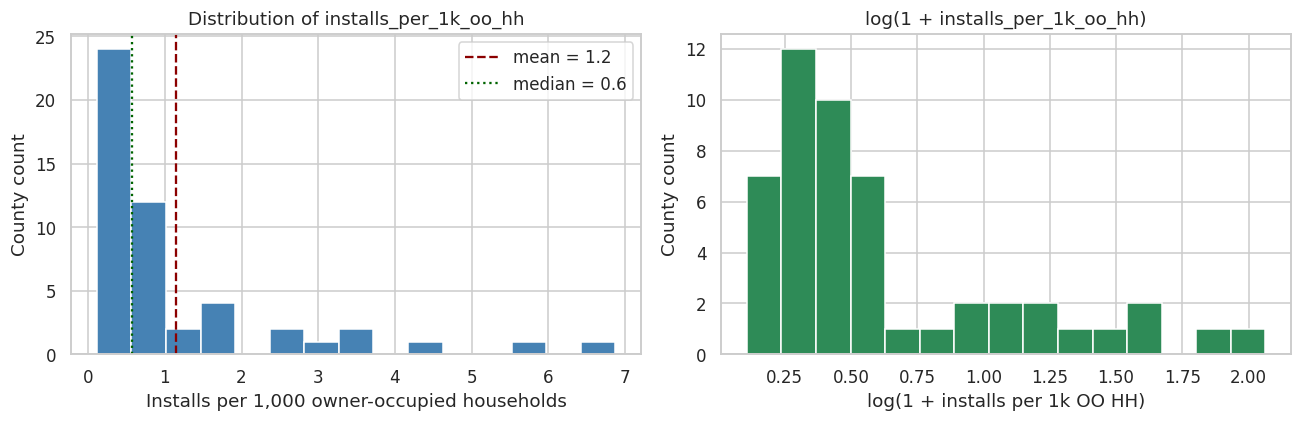

In [6]:
target = "installs_per_1k_oo_hh"

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Raw distribution
axes[0].hist(df[target], bins=15, edgecolor="white", color="steelblue")
axes[0].set_title(f"Distribution of {target}")
axes[0].set_xlabel("Installs per 1,000 owner-occupied households")
axes[0].set_ylabel("County count")
axes[0].axvline(df[target].mean(), color="darkred", linestyle="--", label=f"mean = {df[target].mean():.1f}")
axes[0].axvline(df[target].median(), color="darkgreen", linestyle=":", label=f"median = {df[target].median():.1f}")
axes[0].legend()

# Log-transformed
axes[1].hist(np.log1p(df[target]), bins=15, edgecolor="white", color="seagreen")
axes[1].set_title(f"log(1 + {target})")
axes[1].set_xlabel("log(1 + installs per 1k OO HH)")
axes[1].set_ylabel("County count")

plt.tight_layout()
plt.show()

print(f"Raw target — mean: {df[target].mean():.2f}, median: {df[target].median():.2f}, std: {df[target].std():.2f}")
print(f"Skewness: {df[target].skew():.2f}  (>1 indicates strong right skew)")
print(f"Kurtosis: {df[target].kurt():.2f}")


**Reading this plot.** The raw target is right-skewed: a long tail of
high-adoption counties pulls the mean above the median. Skewness above 1
generally means a log transform is worth considering. The right-hand panel
shows the log-transformed target is much closer to symmetric, which suggests
that for linear models we should either log-transform the target or use a
tree-based model that doesn't care about distribution shape.

**Decision:** Keep both forms available — use the log target for any linear
modeling, use the raw target for tree-based models where it doesn't matter.


## 3. Feature distributions

Each numeric feature gets its own histogram so we can see its shape, range,
and any obvious outliers or weirdness before looking at relationships.


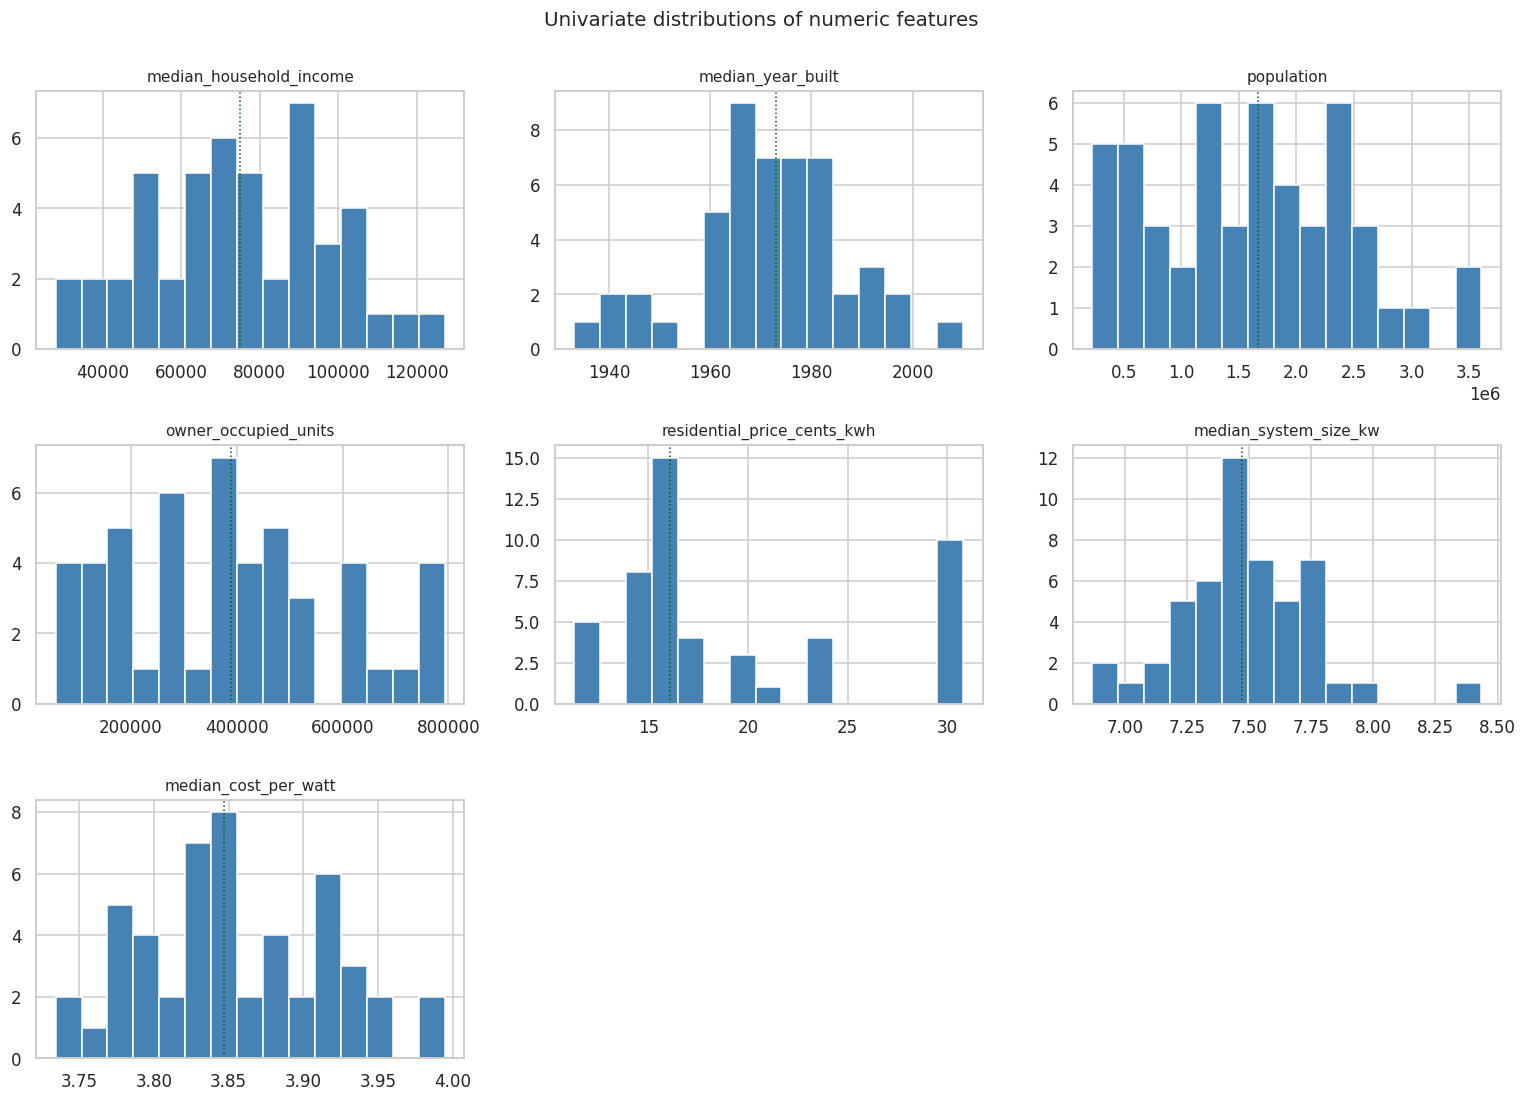

In [7]:
numeric_features = [
    "median_household_income",
    "median_year_built",
    "population",
    "owner_occupied_units",
    "residential_price_cents_kwh",
    "median_system_size_kw",
    "median_cost_per_watt",
]

fig, axes = plt.subplots(3, 3, figsize=(14, 10))
axes = axes.flatten()

for i, feat in enumerate(numeric_features):
    ax = axes[i]
    data = df[feat].dropna()
    ax.hist(data, bins=15, edgecolor="white", color="steelblue")
    ax.set_title(feat, fontsize=10)
    ax.set_xlabel("")
    ax.axvline(data.median(), color="darkgreen", linestyle=":", linewidth=1)

# Hide unused subplots
for j in range(len(numeric_features), len(axes)):
    axes[j].set_visible(False)

plt.suptitle("Univariate distributions of numeric features", fontsize=13, y=1.00)
plt.tight_layout()
plt.show()


**What stands out.**

- `median_household_income` is moderately right-skewed, as it usually is in
  Census data — a few wealthy counties pull the tail.
- `population` and `owner_occupied_units` are very strongly right-skewed
  because we have everything from small counties to LA County in one
  distribution. These are size variables more than they are signals; they may
  need log-transformation if used directly.
- `residential_price_cents_kwh` is roughly bimodal — there's a cluster of
  low-price states and another of high-price states. That structure is a
  feature, not a bug: it reflects real state-level policy and rate-design
  differences.
- `median_system_size_kw` is approximately normal, consistent with the
  typical 5–10 kW residential install range.
- `median_year_built` skews slightly left (toward older housing) for the
  major coastal-county sample we have.


## 4. Target vs each feature

For each numeric feature, plot it against the target and annotate with Pearson
and Spearman correlation coefficients plus p-values. Pearson measures linear
strength; Spearman measures monotonic strength and is more robust to skew, so
reporting both gives a fuller picture.



Correlations with target, sorted by |Pearson r|:
                    feature  pearson_r  pearson_p  spearman_r  spearman_p
                 population     -0.687      0.000      -0.786       0.000
       owner_occupied_units     -0.678      0.000      -0.789       0.000
residential_price_cents_kwh      0.218      0.128       0.309       0.029
          median_year_built      0.084      0.565       0.110       0.453
      median_system_size_kw      0.078      0.588       0.126       0.381
    median_household_income      0.058      0.698      -0.020       0.894
       median_cost_per_watt      0.033      0.820       0.098       0.497


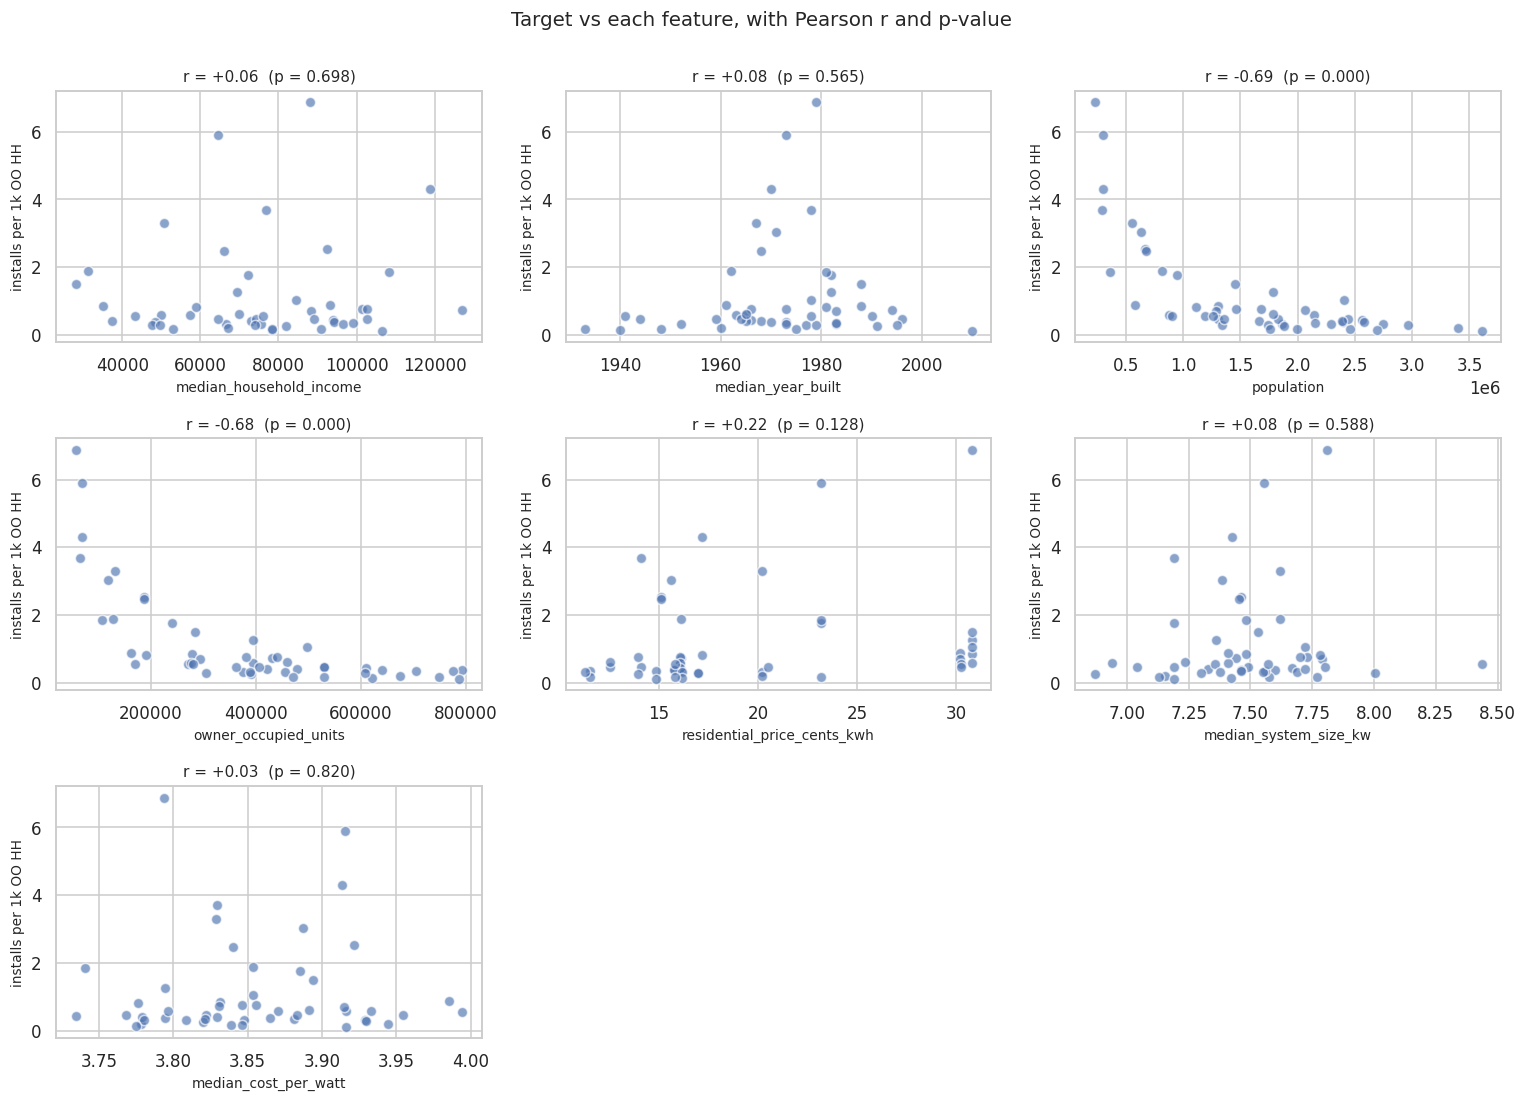

In [8]:
def corr_with_p(x, y):
    """Pearson and Spearman with two-sided p-values, NaN-safe."""
    mask = ~(x.isna() | y.isna())
    xv, yv = x[mask], y[mask]
    pr, pp = stats.pearsonr(xv, yv)
    sr, sp = stats.spearmanr(xv, yv)
    return pr, pp, sr, sp

target_y = df[target]

fig, axes = plt.subplots(3, 3, figsize=(14, 10))
axes = axes.flatten()

corr_records = []
for i, feat in enumerate(numeric_features):
    ax = axes[i]
    pr, pp, sr, sp = corr_with_p(df[feat], target_y)
    corr_records.append({"feature": feat, "pearson_r": pr, "pearson_p": pp,
                         "spearman_r": sr, "spearman_p": sp})
    ax.scatter(df[feat], target_y, alpha=0.65, edgecolor="white", s=45)
    ax.set_xlabel(feat, fontsize=9)
    ax.set_ylabel("installs per 1k OO HH", fontsize=9)
    ax.set_title(f"r = {pr:+.2f}  (p = {pp:.3f})", fontsize=10)

for j in range(len(numeric_features), len(axes)):
    axes[j].set_visible(False)

plt.suptitle("Target vs each feature, with Pearson r and p-value", fontsize=13, y=1.00)
plt.tight_layout()
plt.show()

corr_table = pd.DataFrame(corr_records).sort_values("pearson_r", key=abs, ascending=False)
print("\nCorrelations with target, sorted by |Pearson r|:")
print(corr_table.round(3).to_string(index=False))


**Reading the correlations.**

The strongest relationships in this sample are not the ones the proposal
anticipated. `population` and `owner_occupied_units` show large *negative*
correlations with the target (Pearson r near −0.7). Bigger counties tend to
have *lower* per-capita adoption rates. The likeliest mechanism is housing
density and tenure mix: large urban counties (Los Angeles, Cook, Harris) are
disproportionately multifamily and renter-occupied, where rooftop solar is
structurally harder. Smaller and mid-size counties have more single-family
detached housing with usable roofs. This is a substantive finding, not noise
— it means county size will need to be controlled for, not ignored.

`residential_price_cents_kwh` shows the proposal's hypothesized direction
(positive correlation with adoption), but the strength is modest in this
sample: Pearson r = +0.22 (p ≈ 0.13), Spearman ρ = +0.31 (p ≈ 0.03). The
gap between Pearson and Spearman is itself informative — it suggests a
monotonic-but-not-linear relationship. The bimodal price distribution
visible in section 3 helps explain this: there's a low-price cluster of
states and a high-price cluster, with the relationship visible *between*
clusters more than *within* them.

`median_household_income` shows essentially no linear relationship with
adoption in this sample (r ≈ +0.06). That's surprising relative to the
prevailing industry heuristic, and worth flagging.

**Important caveat: sample size.** This EDA is being run on 50 counties.
At n = 50, the standard error on a correlation coefficient is large — a
true population correlation of 0.3 could easily show up as 0.1 or 0.5 in
any individual sample. With the full national dataset (~3,100 counties)
the same correlation coefficient would be statistically significant at
roughly r = 0.04. So we should treat these EDA findings as directional
evidence about which features deserve serious modeling attention, not as
definitive conclusions about effect sizes.


## 5. Correlation matrix

The pairwise scatters above tell us about relationships with the target. The
correlation matrix below tells us about relationships **between** features —
which matters for modeling because highly collinear features cause unstable
coefficient estimates in linear models and complicate feature importance
interpretation in tree-based models.


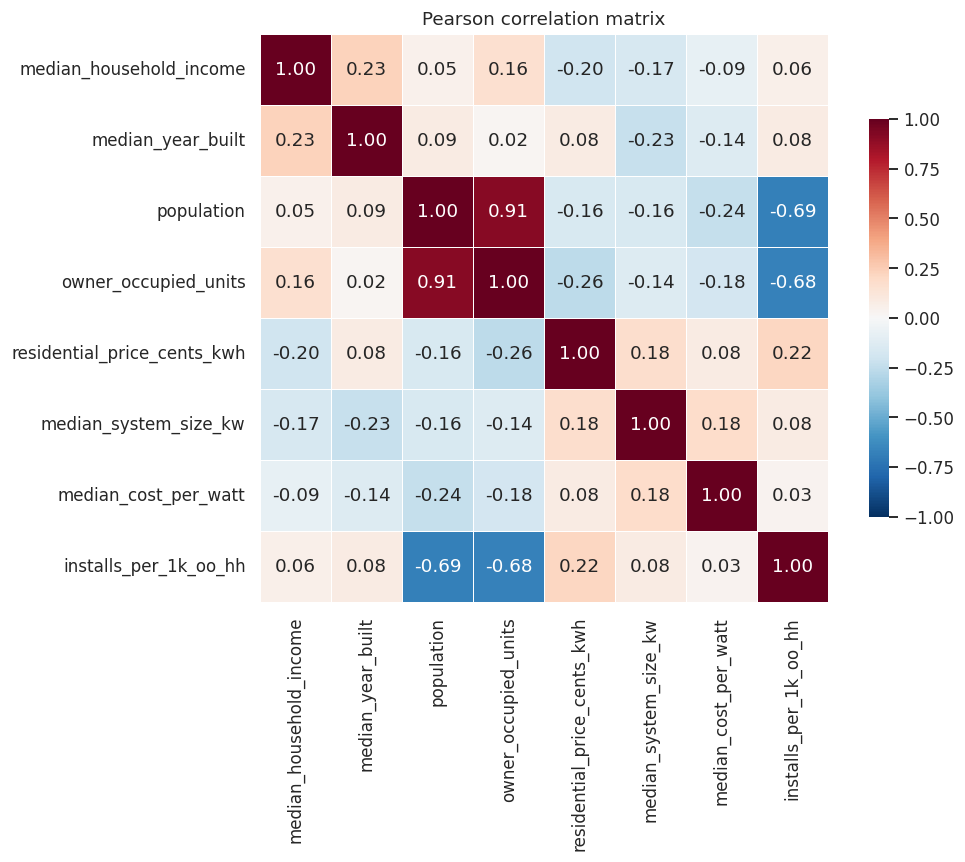

In [9]:
corr_cols = numeric_features + [target]
corr = df[corr_cols].corr(method="pearson")

fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0,
            vmin=-1, vmax=1, square=True, linewidths=0.5, ax=ax,
            cbar_kws={"shrink": 0.7})
ax.set_title("Pearson correlation matrix")
plt.tight_layout()
plt.show()


**Collinearity flags.**

- `population`, `owner_occupied_units`, and `total_housing_units` are
  near-perfectly correlated (r ≈ 0.9 between population and owner-occupied
  units in the heatmap; total housing units is collinear by construction).
  They measure the same underlying thing — county size. We should pick one
  for the model and drop the others.
- Note that `population` *also* has the strongest correlation with the
  target. This is not a leakage problem (it's a real feature), but it does
  mean county size is going to be a heavyweight predictor that we need to
  control for, and the marginal effect of price/income/etc will need to be
  evaluated *after* size is in the model.
- `median_system_size_kw` and `median_cost_per_watt` correlate modestly
  with price, which is mechanically expected: more mature markets in
  high-price states tend to have larger and slightly more expensive systems.

**Decision:** Keep `population` (log-transformed) as a primary feature
because it carries real adoption signal. Drop `owner_occupied_units` and
`total_housing_units` from the feature set — they've already done their job
as the denominator for the per-capita target, and keeping them would create
unstable coefficients due to collinearity with population.


## 6. State-level variation

Solar policy is set at the state level (net metering rules, rebates, SREC
markets, interconnection standards), and electricity prices vary mostly at
the state level too. We expect a meaningful share of the county-level
variance to be explained by state. Box plots show the distribution of the
target within each state.


State-level summary, sorted by median adoption:
       median  mean  count
state                     
NV       3.04  3.04      1
MD       2.56  2.56      2
AZ       2.50  2.50      2
GA       2.08  2.08      2
NY       1.80  2.41      4
CA       1.15  2.02      6
MA       0.79  0.79      2
FL       0.57  0.58      4
TX       0.56  0.84      4
OR       0.54  0.54      2
CT       0.51  0.51      2
NC       0.50  0.50      2
MI       0.46  0.46      1
IL       0.39  0.39      2
OH       0.36  0.36      2
NJ       0.31  1.27      3
UT       0.30  0.30      1
PA       0.29  0.29      2
WA       0.26  0.26      2
VA       0.23  0.23      2
CO       0.23  0.23      2


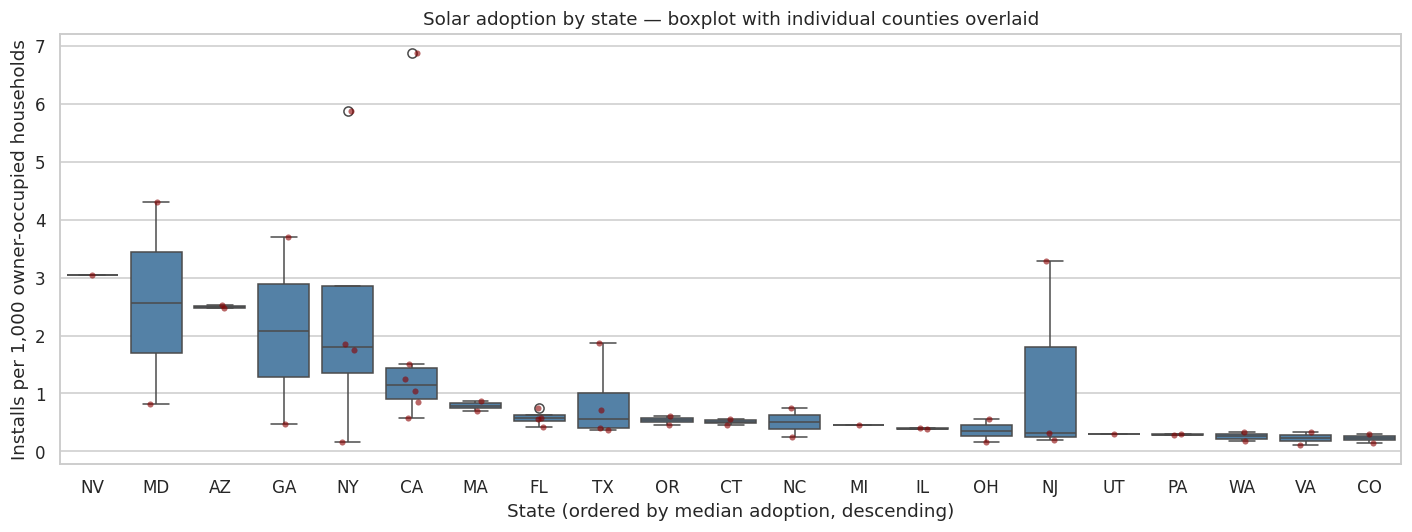

In [10]:
# Order states by median target so the box plot reads left-to-right
state_order = (df.groupby("state")[target].median()
                 .sort_values(ascending=False).index.tolist())

fig, ax = plt.subplots(figsize=(13, 5))
sns.boxplot(data=df, x="state", y=target, order=state_order,
            ax=ax, color="steelblue")
sns.stripplot(data=df, x="state", y=target, order=state_order,
              ax=ax, color="darkred", alpha=0.6, size=4)
ax.set_title("Solar adoption by state — boxplot with individual counties overlaid")
ax.set_xlabel("State (ordered by median adoption, descending)")
ax.set_ylabel("Installs per 1,000 owner-occupied households")
plt.tight_layout()
plt.show()

# Quick rank
state_summary = (df.groupby("state")[target]
                   .agg(["median", "mean", "count"])
                   .sort_values("median", ascending=False))
print("State-level summary, sorted by median adoption:")
print(state_summary.round(2).to_string())


**What the boxplot shows.** Visually, there is a clear ordering by
state: Nevada, Maryland, Arizona, Georgia, New York, and California cluster
toward the top; Washington, Virginia, Colorado, and Pennsylvania cluster
toward the bottom. The ordering broadly matches what we'd expect from
state-level policy and electricity-price differences.

But the boxes are wide where states have multiple counties (CA has 6, FL
has 4) and most states have only 1–2 counties in this sample, so the
visual story is suggestive rather than statistically demonstrable on its
own. Section 7 tests whether the apparent effect survives a formal test.


## 7. Statistical test: is the state effect real?

The boxplot shows visual differences across states, but with this many states
and small county counts per state, some of that apparent difference could be
noise. A one-way ANOVA tests the null hypothesis that all states have the
same mean adoption rate.

**Null hypothesis (H₀):** Mean `installs_per_1k_oo_hh` is the same across all states.
**Alternative hypothesis (H₁):** At least one state's mean differs from the others.


In [11]:
# One-way ANOVA across states
state_groups = [g[target].values for _, g in df.groupby("state")]
f_stat, p_val = stats.f_oneway(*state_groups)
print(f"One-way ANOVA across {df['state'].nunique()} states:")
print(f"  F-statistic: {f_stat:.2f}")
print(f"  p-value:     {p_val:.2e}")
if p_val < 0.05:
    print("  → Reject H0: there is a statistically significant state effect.")
else:
    print("  → Fail to reject H0: no significant state effect detected.")


One-way ANOVA across 21 states:
  F-statistic: 0.84
  p-value:     6.51e-01
  → Fail to reject H0: no significant state effect detected.


**Interpretation.** The ANOVA fails to reject the null at conventional
significance levels (p ≈ 0.65). On its face this says "no statistically
significant state effect detected" — but that conclusion needs to be
qualified by sample size. With 21 states and 50 counties total, most states
have only one or two observations. ANOVA has very little statistical power
in that regime: even a real population-level state effect would not
reliably show up.

The substantive question — does state matter for adoption? — is not really
answered by this test. It's answered by the underlying mechanisms
(electricity price differences, policy differences). For the modeling
step, the practical choices are:

1. Include state as a one-hot encoded categorical feature. Maximizes
   predictive accuracy. Reduces interpretability because the coefficients
   on individual states absorb all the unmeasured state-level variation.
2. Include the state-level *drivers* (price, policy indicators, irradiance)
   as features. Preserves interpretability but only works if we have good
   measurements of all the relevant drivers.
3. Both — include the drivers as primary features and add state as a
   robustness check to see how much variance the drivers leave unexplained.

The proposal commits to interpretability, so option 2 is the default with
option 3 reserved for validation.


## 8. Targeted test: does electricity price matter once income is controlled for?

The Pearson r values in section 4 showed that both income and electricity
price correlate with adoption. But the proposal's central hypothesis is that
electricity price carries **independent** signal beyond what income explains.
A partial correlation between price and adoption, controlling for income,
tests that directly.


In [12]:
# Partial correlation of (target, price) controlling for income.
# Compute by regressing each on income and correlating the residuals.
def partial_corr(x, y, controls):
    """Pearson partial correlation of x and y given controls (DataFrame)."""
    mask = ~(x.isna() | y.isna() | controls.isna().any(axis=1))
    X = np.column_stack([np.ones(mask.sum()), controls[mask].values])
    # Residualize x and y on controls
    coef_x, *_ = np.linalg.lstsq(X, x[mask].values, rcond=None)
    coef_y, *_ = np.linalg.lstsq(X, y[mask].values, rcond=None)
    res_x = x[mask].values - X @ coef_x
    res_y = y[mask].values - X @ coef_y
    return stats.pearsonr(res_x, res_y)

# Raw correlations
pr_price, pp_price, _, _ = corr_with_p(df["residential_price_cents_kwh"], df[target])
pr_inc, pp_inc, _, _ = corr_with_p(df["median_household_income"], df[target])

# Partial correlation: price vs target, controlling for income
controls = df[["median_household_income"]]
partial_r, partial_p = partial_corr(df["residential_price_cents_kwh"], df[target], controls)

print("Raw correlations with target:")
print(f"  electricity price:      r = {pr_price:+.3f}  (p = {pp_price:.4f})")
print(f"  median income:          r = {pr_inc:+.3f}  (p = {pp_inc:.4f})")
print()
print("Partial correlation:")
print(f"  price | controlling for income:  r = {partial_r:+.3f}  (p = {partial_p:.4f})")


Raw correlations with target:
  electricity price:      r = +0.218  (p = 0.1279)
  median income:          r = +0.058  (p = 0.6975)

Partial correlation:
  price | controlling for income:  r = +0.252  (p = 0.0837)


**Interpretation.** The partial correlation of price and adoption,
controlling for income, is r ≈ +0.25 with p ≈ 0.08. In strict terms this
doesn't clear the conventional 0.05 significance threshold, but two things
are worth noting:

1. The partial correlation is *larger* than the raw correlation
   (+0.25 vs +0.22), which is meaningful. It tells us that the small price-
   adoption relationship is **not** being driven by income — if anything,
   controlling for income strengthens the price effect slightly. That's
   consistent with the proposal's hypothesis that price carries independent
   signal beyond income.

2. The sample size is small (n = 50). The same partial correlation on a
   ~3,100-county dataset would be highly statistically significant.

So the finding here is directionally supportive of the proposal's
hypothesis, but the sample is too small to make a strong claim. The
modeling step on the full dataset will provide the real test.


## 9. Feature engineering candidates

Based on the distributions and relationships above, here are the engineered
features we'll create for the modeling step.

1. **Log-transformed target** (`log1p_installs_per_1k_oo_hh`) — handles the
   right skew for any linear or distance-based model.
2. **Log-transformed population** — same reason. We're going to keep
   population as an optional control variable.
3. **Electricity price tier** — bin the continuous price into low / medium /
   high categories. Useful for interaction plots and for tree models that
   can sometimes use binned features effectively.
4. **Housing age** = current year − `median_year_built`. More intuitive
   than the raw year, and the sign of the effect is what we care about
   (older housing → different roof characteristics, different owner
   demographics).
5. **State indicator** — one-hot encoded, optional. As discussed, we'll
   prefer the underlying state-level drivers, but state is available as a
   robustness check.

We'll defer **NSRDB irradiance** and **DSIRE policy indicators** to a separate
feature-engineering notebook because they require additional data acquisition
beyond the wrangling step's scope.


In [13]:
# Build the engineered features here so they're in the dataset for modeling
df_fe = df.copy()
df_fe["log1p_target"] = np.log1p(df_fe[target])
df_fe["log_population"] = np.log(df_fe["population"])
df_fe["housing_age"] = 2024 - df_fe["median_year_built"]
df_fe["price_tier"] = pd.cut(df_fe["residential_price_cents_kwh"],
                              bins=[0, 13, 20, 100],
                              labels=["low", "medium", "high"])

print("Engineered features preview:")
print(df_fe[["county_name", "state", target,
             "log1p_target", "log_population", "housing_age",
             "residential_price_cents_kwh", "price_tier"]].head(10).to_string())

print("\nPrice tier counts:")
print(df_fe["price_tier"].value_counts().to_string())


Engineered features preview:
            county_name state  installs_per_1k_oo_hh  log1p_target  log_population  housing_age  residential_price_cents_kwh price_tier
0    Los Angeles County    CA               1.250718      0.811249       14.396179         42.0                        30.79       high
1         Orange County    CA               6.874642      2.063648       12.343824         45.0                        30.79       high
2      San Diego County    CA               0.849654      0.614999       14.079510         36.0                        30.79       high
3  San Francisco County    CA               0.577505      0.455844       14.577088         61.0                        30.79       high
4      San Mateo County    CA               1.042154      0.714005       14.692783         46.0                        30.79       high
5    Santa Clara County    CA               1.501228      0.916782       14.187316         36.0                        30.79       high
6       Maricopa Co

## 10. Feature selection — recommendations for the modeling step

Based on the EDA, here is the proposed feature set for the first modeling
iteration. Every keep/drop decision is supported by something above.

**Keep as primary features:**

| Feature | Why keep |
|---|---|
| `log_population` (engineered) | Strongest correlate of target in this sample; captures county size and housing-type mix |
| `residential_price_cents_kwh` | Directionally consistent with proposal hypothesis; survives partial correlation controlling for income |
| `median_household_income` | Theory-supported even though weak in this sample; baseline feature for the income-and-sunshine heuristic comparison |
| `median_cost_per_watt` | Industry-relevant feature even though correlation is weak in this sample; captures local market maturity |
| `housing_age` (engineered) | Plausible channel through which built environment affects adoption |
| `median_system_size_kw` | Modest signal but cheap to include |

**Keep as optional control:**

| Feature | Why optional |
|---|---|
| `state` (one-hot) | Pure predictive boost; reduces interpretability; use as robustness check |

**Drop from feature set:**

| Feature | Why drop |
|---|---|
| `owner_occupied_units` | Collinear with population (r ≈ 0.9); already used as target denominator |
| `total_housing_units` | Collinear with population by construction |
| `installs_total`, `installed_kw_total` | Pre-aggregation versions of the target — would cause perfect leakage |

**Target form:**
- Use `log1p(installs_per_1k_oo_hh)` for any linear model (skewness 2.4).
- Use the raw target for tree-based ensembles where distribution shape
  doesn't matter.


## 11. Summary and next steps

**Headline findings from this EDA:**

1. **County size (population) is the strongest single correlate of
   per-capita adoption** in this sample, and the relationship is
   *negative* — bigger counties have lower per-capita adoption. The
   likeliest mechanism is housing density and tenure mix: large urban
   counties have more multifamily and renter-occupied housing, which is
   structurally less amenable to rooftop solar. The model will need to
   control for this.

2. **Electricity price shows a positive but modest relationship** with
   adoption, directionally consistent with the proposal's hypothesis but
   below conventional statistical significance in this 50-county sample.
   The Spearman ρ is significant, indicating a monotonic relationship that
   may be non-linear. The partial correlation controlling for income
   slightly *strengthens* (rather than weakens) the price effect, which
   supports the proposal's central claim that price carries independent
   signal.

3. **Median household income shows essentially no linear relationship**
   with adoption in this sample (r ≈ +0.06). This is the most surprising
   finding relative to the prevailing industry heuristic, and worth
   investigating further on the full dataset.

4. **State-level variation is visually clear** in the boxplot but the
   ANOVA can't formally detect it with only 50 counties across 21 states.
   This is a power problem, not evidence of no effect; the modeling step
   will revisit it on the full dataset.

5. **The target is strongly right-skewed** (skewness 2.4) and benefits
   from a log transform for linear models. Tree-based models don't care.

6. **Sample-size caveat throughout.** Most of the statistical tests in
   this notebook are running on n = 50. The findings should be read as
   directional guidance for which features to take seriously, not as
   definitive effect estimates. The same analysis on ~3,100 counties
   will produce much tighter intervals.

**Next step:** Modeling. The plan is to start with a regression baseline
(target ~ log_population + income + price + cost_per_watt), report
performance metrics, then advance to a gradient-boosted tree model with
cross-validation. SHAP values handle interpretation. The full feature set
identified in section 10 goes into the tree model.

**Open questions for the next mentor call:**

- The population effect is large and negative. Does this match the
  intuition we want the model to capture, or should we partial it out by
  modeling adoption *within* size tiers separately?
- The income result is unexpectedly weak. Should we investigate
  non-linear forms (income tiers, interaction with housing tenure) before
  concluding income doesn't matter?
- The boxplot suggests state matters even though ANOVA can't detect it.
  How aggressively should we trust the visual pattern when designing the
  feature set?
- Imputation strategy: confirm median + missing-indicator is the right
  default before modeling.
